<a href="https://colab.research.google.com/github/alyPoint/CEFET---Processamento-de-Sinais-I-140826/blob/main/Pratica_6/DSP_1_PRATICA_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Questão 1**

### **Letra a**

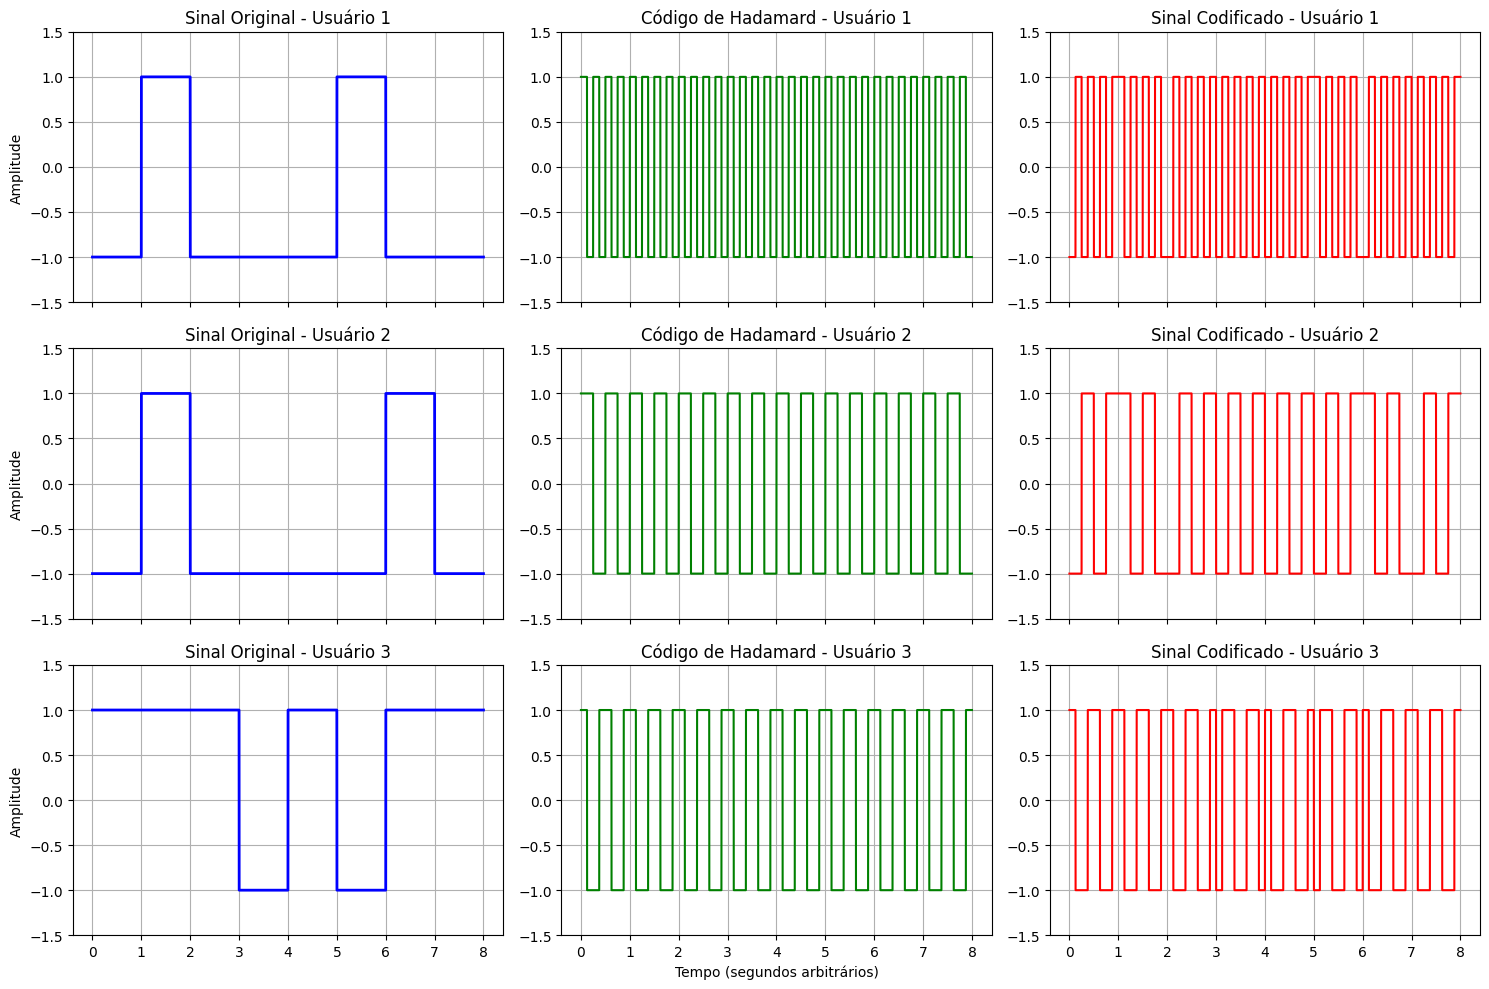

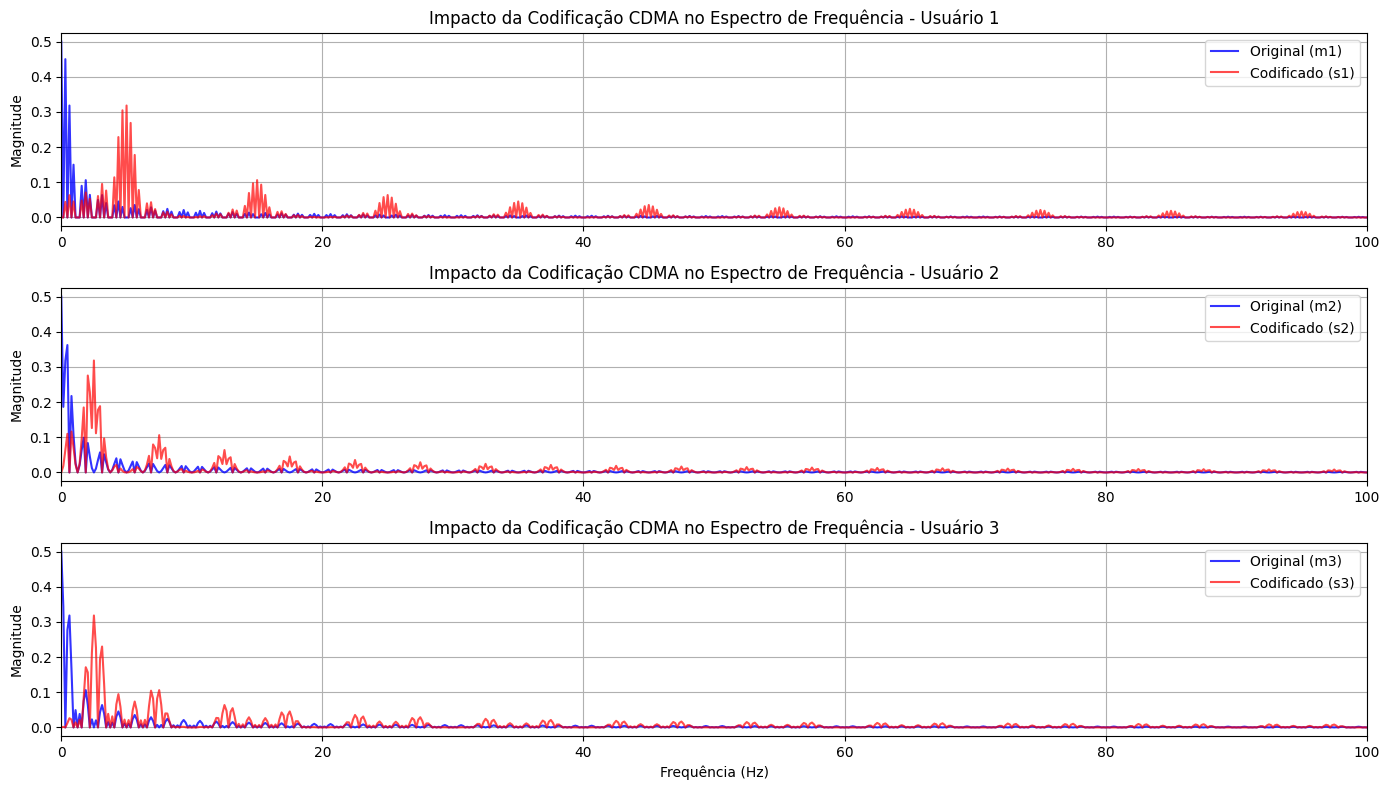

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import hadamard

# ==========================================
# 1. CONFIGURAÇÕES INICIAIS E GERAÇÃO DE DADOS
# ==========================================
np.random.seed(42)  # Semente para reprodutibilidade
N = 8               # Comprimento da sequência de bits e ordem da matriz de Hadamard
fs = 1000           # Frequência de amostragem para visualização do espectro (Hz)
samples_per_bit = 100  # Amostras por chip/bit para suavizar a forma de onda temporal

# Gerando mensagens originais m[n] em {-1, 1} de comprimento N=8 para 3 usuários
m1 = np.random.choice([-1, 1], N)
m2 = np.random.choice([-1, 1], N)
m3 = np.random.choice([-1, 1], N)

# ==========================================
# 2. GERAÇÃO DOS CÓDIGOS DE HADAMARD
# ==========================================
# A função hadamard(8) gera uma matriz 8x8 ortogonal
H = hadamard(N)
c1 = H[1, :]  # Código do Usuário 1 (Linha 1)
c2 = H[2, :]  # Código do Usuário 2 (Linha 2)
c3 = H[3, :]  # Código do Usuário 3 (Linha 3)

# ==========================================
# 3. CODIFICAÇÃO CDMA (ESPALHAMENTO ESPECTRAL)
# ==========================================
# O espalhamento é feito multiplicando cada bit do usuário pelo código de Hadamard completo.
# Alternativamente, pode ser visto como o produto kronecker ou expansão chip a chip.
s1 = np.kron(m1, c1)
s2 = np.kron(m2, c2)
s3 = np.kron(m3, c3)

# ==========================================
# 4. PREPARAÇÃO DOS SINAIS PARA GRÁFICOS TEMPORAIS
# ==========================================
# Para exibir os bits originais mantendo a duração total coerente com o sinal espalhado:
# Cada bit original possui N chips, logo sua duração visual deve abranger N * samples_per_bit por bit.
m1_upsampled = np.repeat(m1, N * samples_per_bit)
m2_upsampled = np.repeat(m2, N * samples_per_bit)
m3_upsampled = np.repeat(m3, N * samples_per_bit)

# Repetição dos códigos de Hadamard ao longo de todos os bits
c1_upsampled = np.tile(np.repeat(c1, samples_per_bit), N)
c2_upsampled = np.tile(np.repeat(c2, samples_per_bit), N)
c3_upsampled = np.tile(np.repeat(c3, samples_per_bit), N)

# Sinais espalhados (comprimento total = N * N chips)
s1_upsampled = np.repeat(s1, samples_per_bit)
s2_upsampled = np.repeat(s2, samples_per_bit)
s3_upsampled = np.repeat(s3, samples_per_bit)

# Vetor de tempo total
t = np.linspace(0, N, len(s1_upsampled))

# ==========================================
# 5. VISUALIZAÇÃO NO DOMÍNIO DO TEMPO (3 USUÁRIOS)
# ==========================================
fig, axs = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
signals = [
    (m1_upsampled, c1_upsampled, s1_upsampled, 'Usuário 1'),
    (m2_upsampled, c2_upsampled, s2_upsampled, 'Usuário 2'),
    (m3_upsampled, c3_upsampled, s3_upsampled, 'Usuário 3')
]

for i, (m, c, s, name) in enumerate(signals):
    # Sinal Original
    axs[i, 0].plot(t, m, 'b', linewidth=2)
    axs[i, 0].set_title(f'Sinal Original - {name}')
    axs[i, 0].grid(True)
    axs[i, 0].set_ylim(-1.5, 1.5)
    axs[i, 0].set_ylabel('Amplitude')

    # Código de Hadamard
    axs[i, 1].plot(t, c, 'g', linewidth=1.5)
    axs[i, 1].set_title(f'Código de Hadamard - {name}')
    axs[i, 1].grid(True)
    axs[i, 1].set_ylim(-1.5, 1.5)

    # Sinal Codificado (Espalhado)
    axs[i, 2].plot(t, s, 'r', linewidth=1.5)
    axs[i, 2].set_title(f'Sinal Codificado - {name}')
    axs[i, 2].grid(True)
    axs[i, 2].set_ylim(-1.5, 1.5)

axs[2, 1].set_xlabel('Tempo (segundos arbitrários)')
plt.tight_layout()
plt.show()

# ==========================================
# 6. CÁLCULO E VISUALIZAÇÃO DO ESPECTRO DE FREQUÊNCIA
# ==========================================
def calcular_espectro(sinal, fs):
    N_fft = len(sinal)
    freq = np.fft.fftfreq(N_fft, d=1/fs)
    espectro = np.abs(np.fft.fft(sinal)) / N_fft
    half = N_fft // 2
    return freq[:half], espectro[:half]

# Calculando para os 3 usuários
f_m1, E_m1 = calcular_espectro(m1_upsampled, fs)
f_s1, E_s1 = calcular_espectro(s1_upsampled, fs)

f_m2, E_m2 = calcular_espectro(m2_upsampled, fs)
f_s2, E_s2 = calcular_espectro(s2_upsampled, fs)

f_m3, E_m3 = calcular_espectro(m3_upsampled, fs)
f_s3, E_s3 = calcular_espectro(s3_upsampled, fs)

# Plotando os Espectros Comparativos
plt.figure(figsize=(14, 8))

plt.subplot(3, 1, 1)
plt.plot(f_m1, E_m1, 'b', label='Original (m1)', alpha=0.8)
plt.plot(f_s1, E_s1, 'r', label='Codificado (s1)', alpha=0.7)
plt.title('Impacto da Codificação CDMA no Espectro de Frequência - Usuário 1')
plt.ylabel('Magnitude')
plt.xlim(0, 100)
plt.legend(loc='upper right')
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(f_m2, E_m2, 'b', label='Original (m2)', alpha=0.8)
plt.plot(f_s2, E_s2, 'r', label='Codificado (s2)', alpha=0.7)
plt.title('Impacto da Codificação CDMA no Espectro de Frequência - Usuário 2')
plt.ylabel('Magnitude')
plt.xlim(0, 100)
plt.legend(loc='upper right')
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(f_m3, E_m3, 'b', label='Original (m3)', alpha=0.8)
plt.plot(f_s3, E_s3, 'r', label='Codificado (s3)', alpha=0.7)
plt.title('Impacto da Codificação CDMA no Espectro de Frequência - Usuário 3')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude')
plt.xlim(0, 100)
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

**Comentário sobre o Impacto da Codificação no Espectro do Sinal Espalhamento Espectral (Spread Spectrum):**

O sinal de dados original m[n] possui uma taxa de variação mais lenta (transições de bits espaçadas), o que concentra a maior parte da sua energia em frequências mais baixas (próximas a 0 Hz). Quando multiplicamos esse sinal pelo código de Hadamard c[n], que introduz variações de alta frequência (chips), ocorre a expansão da largura de banda do sinal no domínio da frequência.

---

**Redução da Densidade Espectral de Potência (DEP):**
Como a energia total do sinal é distribuída por uma faixa de frequências muito maior (devido aos chips de Hadamard de alta frequência), a magnitude espectral de pico do sinal codificado diminui consideravelmente em comparação ao sinal original. Isso torna o sinal CDMA mais resistente a interferências de banda estreita e confere propriedades de espalhamento semelhantes a ruído (baixo perfil de interceptação).

---

**Ortogonalidade:**
Como as linhas da matriz de Hadamard formam um conjunto de códigos perfeitamente ortogonais entre si, os três usuários podem ocupar exatamente a mesma faixa de frequência e o mesmo intervalo de tempo simultaneamente sem sofrer interferência mútua no receptor, desde que a des-espalhamento seja feito com o respectivo código correto.

### **Letra b**

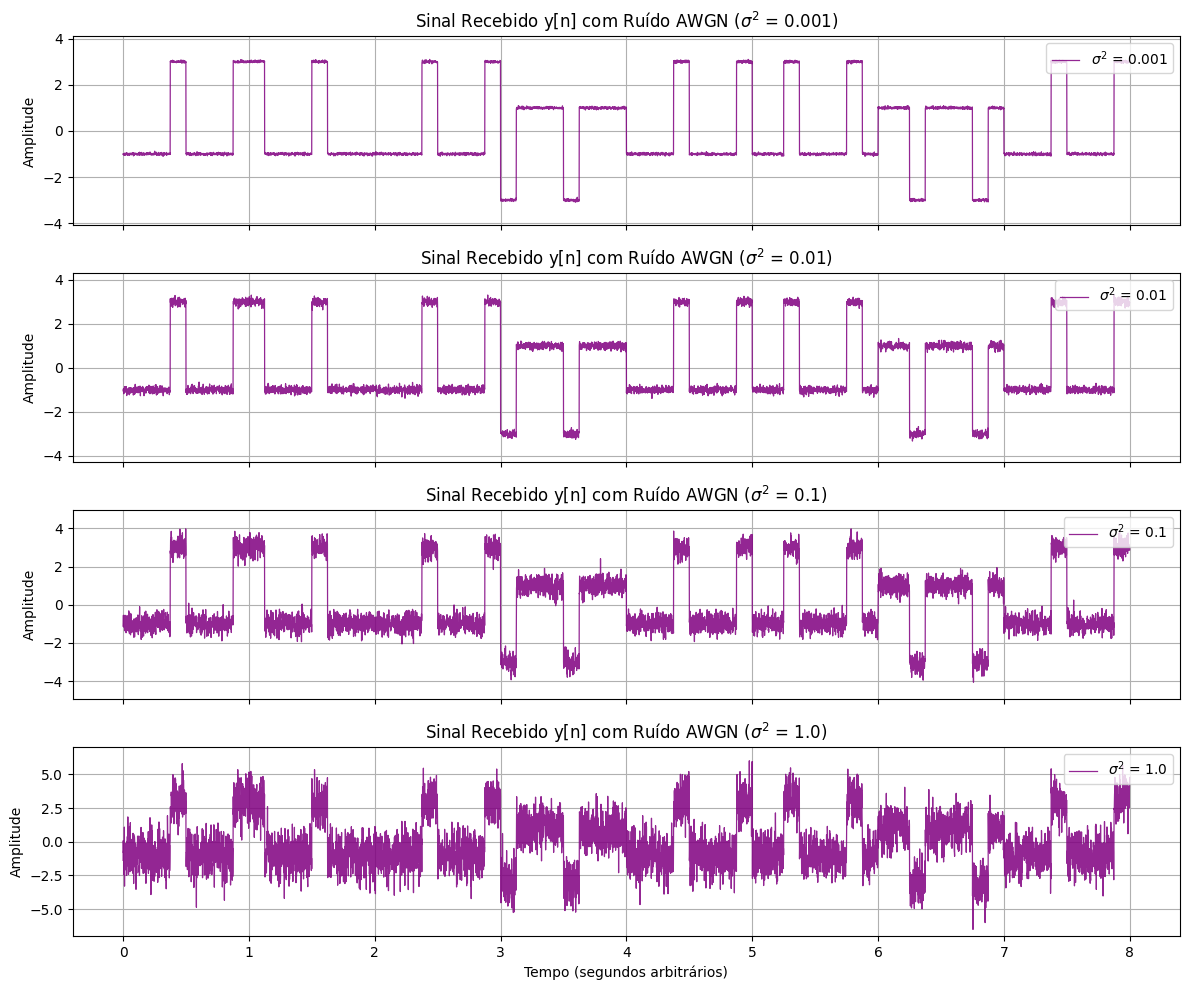

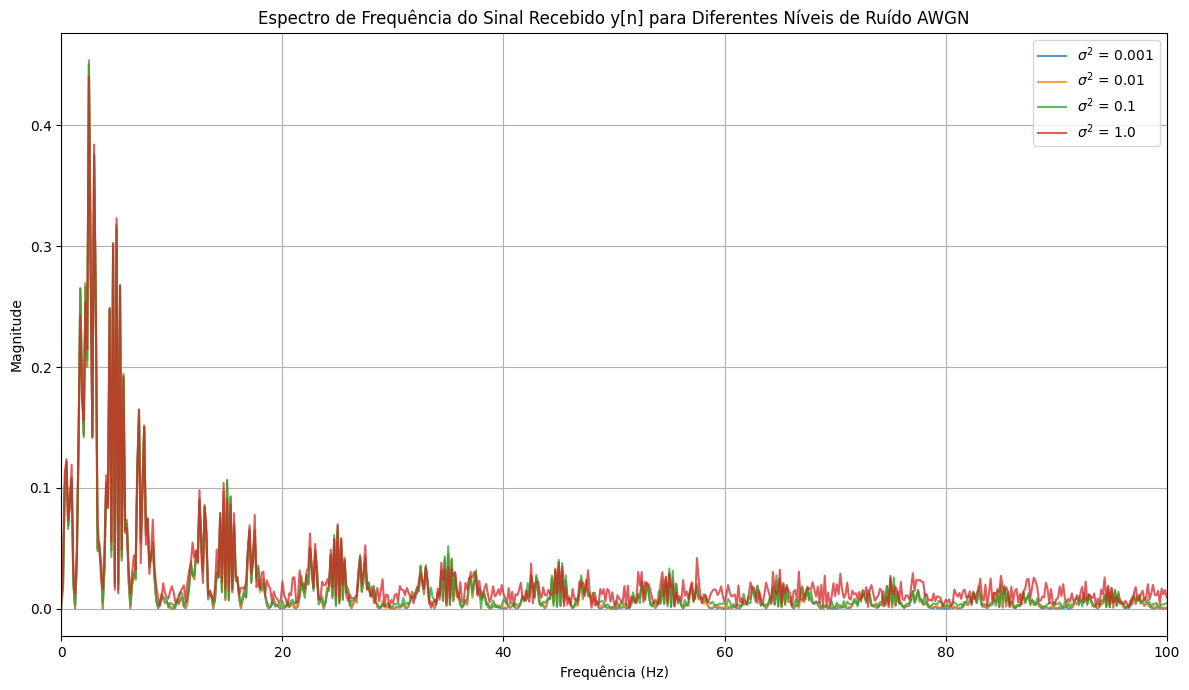

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import hadamard

# ==========================================
# 1. RECONSTRUÇÃO DOS SINAIS DOS USUÁRIOS
# ==========================================
np.random.seed(42)  # Mesma semente para garantir consistência
N = 8
fs = 1000
samples_per_bit = 100

# Mensagens originais
m1 = np.random.choice([-1, 1], N)
m2 = np.random.choice([-1, 1], N)
m3 = np.random.choice([-1, 1], N)

# Matriz de Hadamard e Códigos
H = hadamard(N)
c1 = H[1, :]
c2 = H[2, :]
c3 = H[3, :]

# Sinais codificados (espalhados)
s1 = np.kron(m1, c1)
s2 = np.kron(m2, c2)
s3 = np.kron(m3, c3)

# Formas de onda upsampled (contínuas por partes)
s1_upsampled = np.repeat(s1, samples_per_bit)
s2_upsampled = np.repeat(s2, samples_per_bit)
s3_upsampled = np.repeat(s3, samples_per_bit)

# Sinal combinado dos 3 usuários (sem ruído)
x_sum = s1_upsampled + s2_upsampled + s3_upsampled
t = np.linspace(0, N, len(x_sum))

# Variâncias do ruído AWGN a serem avaliadas
sigma_sq_list = [1e-3, 1e-2, 1e-1, 1.0]

# ==========================================
# 2. VISUALIZAÇÃO NO DOMÍNIO DO TEMPO
# ==========================================
fig, axs = plt.subplots(len(sigma_sq_list), 1, figsize=(12, 10), sharex=True)

for i, sigma_sq in enumerate(sigma_sq_list):
    sigma = np.sqrt(sigma_sq)
    # Geração do ruído AWGN w[n] ~ N(0, sigma^2)
    w = np.random.normal(0, sigma, size=len(x_sum))

    # Sinal recebido y[n]
    y = x_sum + w

    axs[i].plot(t, y, color='purple', linewidth=0.9, alpha=0.85, label=f'$\\sigma^2$ = {sigma_sq}')
    axs[i].set_title(f'Sinal Recebido y[n] com Ruído AWGN ($\\sigma^2$ = {sigma_sq})')
    axs[i].set_ylabel('Amplitude')
    axs[i].grid(True)
    axs[i].legend(loc='upper right')
    axs[i].set_ylim(-4 - 3*sigma, 4 + 3*sigma)

axs[-1].set_xlabel('Tempo (segundos arbitrários)')
plt.tight_layout()
plt.show()

# ==========================================
# 3. CÁLCULO E VISUALIZAÇÃO DO ESPECTRO DE y[n]
# ==========================================
def calcular_espectro(sinal, fs):
    N_fft = len(sinal)
    freq = np.fft.fftfreq(N_fft, d=1/fs)
    espectro = np.abs(np.fft.fft(sinal)) / N_fft
    half = N_fft // 2
    return freq[:half], espectro[:half]

plt.figure(figsize=(12, 7))

for sigma_sq in sigma_sq_list:
    sigma = np.sqrt(sigma_sq)
    w = np.random.normal(0, sigma, size=len(x_sum))
    y = x_sum + w

    freqs, espectro = calcular_espectro(y, fs)
    plt.plot(freqs, espectro, alpha=0.75, label=f'$\\sigma^2$ = {sigma_sq}')

plt.title('Espectro de Frequência do Sinal Recebido y[n] para Diferentes Níveis de Ruído AWGN')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude')
plt.xlim(0, 100)
plt.legend(loc='upper right')
plt.grid(True)
plt.tight_layout()
plt.show()

### **Comentários sobre o Impacto de $\sigma^2$**
1. **Domínio do Tempo:**
- Baixa Variância ($\sigma^2 = 10^{-3}$ e $10^{-2}$): O ruído é quase
imperceptível. A forma de onda combinada dos três usuários ($x_1 + x_2 + x_3$) permanece nítida, com transições bem definidas e amplitudes que refletem a sobreposição construtiva/destrutiva dos chips de Hadamard.
- Alta Variância ($\sigma^2 = 1$): O ruído gaussiano domina visualmente a forma de onda. As transições dos bits e chips ficam severamente distorcidas e mascaradas pelas flutuações estocásticas de alta amplitude, o que exigirá o processo de correlação (des-espalhamento) no receptor para recuperar os dados originais.

---

2. **Espectro de Frequência:**
- Elevação do Piso de Ruído (Noise Floor): Como o ruído AWGN possui uma densidade espectral de potência plana (branco) em todas as frequências, o aumento de $\sigma^2$ eleva de maneira uniforme a magnitude do piso de ruído em todo o espectro.
- Mascaramento Espectral: Para $\sigma^2 = 1$, o nível do ruído se torna comparável ou superior às componentes espectrais do sinal útil, dificultando a identificação visual das características de banda dos sinais espalhados e degradando a relação sinal-ruído (SNR) do canal.

### **Letra d**

<>:70: SyntaxWarning: invalid escape sequence '\s'
<>:71: SyntaxWarning: invalid escape sequence '\s'
<>:70: SyntaxWarning: invalid escape sequence '\s'
<>:71: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1483/338777222.py:70: SyntaxWarning: invalid escape sequence '\s'
  plt.title('Taxa de Erro de Bit (BER) em Função da Variância do Ruído ($\sigma^2$)')
/tmp/ipykernel_1483/338777222.py:71: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('Variância do Ruído ($\sigma^2$) [Escala Logarítmica]')


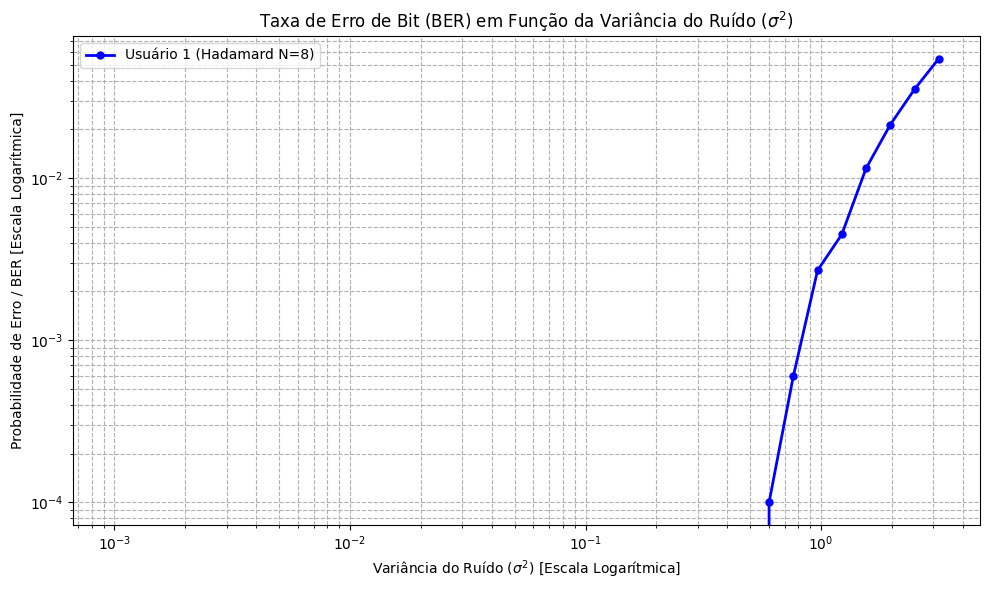

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import hadamard

# ==========================================
# 1. CONFIGURAÇÕES E GERAÇÃO DO FLUXO DE DADOS
# ==========================================
np.random.seed(42)
N = 8              # Comprimento do código de Hadamard / chips por bit
num_bits = 10000   # Número de bits transmitidos para obter estatísticas robustas de BER

# Gerando fluxos de bits originais para os 3 usuários
m1 = np.random.choice([-1, 1], num_bits)
m2 = np.random.choice([-1, 1], num_bits)
m3 = np.random.choice([-1, 1], num_bits)

# Geração dos códigos de Hadamard ortogonais
H = hadamard(N)
c1 = H[1, :]
c2 = H[2, :]
c3 = H[3, :]

# Sinais codificados (espalhados) de cada usuário
s1 = np.kron(m1, c1)
s2 = np.kron(m2, c2)
s3 = np.kron(m3, c3)

# Sinal combinado no canal (antes do ruído)
x_sum = s1 + s2 + s3

# ==========================================
# 2. SIMULAÇÃO DA BER EM FUNÇÃO DE \sigma^2
# ==========================================
# Definindo uma faixa de valores para a variância do ruído AWGN (\sigma^2)
sigma_sq_values = np.logspace(-3, 0.5, 35)  # de 1e-3 a ~3.16
ber_user1 = []

for sigma_sq in sigma_sq_values:
    sigma = np.sqrt(sigma_sq)

    # Geração do ruído AWGN w[n] ~ N(0, \sigma^2)
    w = np.random.normal(0, sigma, size=len(x_sum))

    # Sinal recebido y[n]
    y = x_sum + w

    # --- RECEPTOR CDMA (DES-ESPALHAMENTO PARA O USUÁRIO 1) ---
    # Reorganiza o sinal recebido em matriz de blocos (num_bits x N chips)
    y_matrix = y.reshape(num_bits, N)

    # Correlação: produto interno de cada linha com o código c1, dividido por N (ganho de processamento)
    correlation = np.dot(y_matrix, c1) / N

    # Tomada de decisão (função sinal para recuperar {-1, 1})
    m1_est = np.sign(correlation)
    m1_est[m1_est == 0] = 1  # Tratamento para casos exatos em zero

    # --- COMPARAÇÃO E CÁLCULO DA BER ---
    errors = np.sum(m1_est != m1)
    ber = errors / num_bits
    ber_user1.append(ber)

# ==========================================
# 3. PLOTAGEM DO GRÁFICO DE PROBABILIDADE DE ERRO
# ==========================================
plt.figure(figsize=(10, 6))
plt.plot(sigma_sq_values, ber_user1, 'bo-', linewidth=2, markersize=5, label='Usuário 1 (Hadamard N=8)')
plt.xscale('log')
plt.yscale('log')
plt.title('Taxa de Erro de Bit (BER) em Função da Variância do Ruído ($\sigma^2$)')
plt.xlabel('Variância do Ruído ($\sigma^2$) [Escala Logarítmica]')
plt.ylabel('Probabilidade de Erro / BER [Escala Logarítmica]')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.show()

1. **Comportamento em Baixos Níveis de Ruído ($\sigma^2 \le 10^{-2}$):**
- Para valores pequenos de $\sigma^2$, a curva de BER aponta zero erros ($\text{BER} = 0$).
- Isso ocorre porque o ganho de processamento proporcionado pelo comprimento do código de Hadamard ($N = 8$) atua filtrando o ruído gaussiano (conforme demonstrado analiticamente na relação $\sigma^2 / N$). O nível de ruído é insuficiente para alterar o sinal da correlação, permitindo que a função $\text{sign}(\cdot)$ recupere o bit original $\hat{m}_1[n]$ com total fidelidade.

---

2. **Transição e Degradação em Altos Níveis de Ruído ($\sigma^2 \to 1$):**
- À medida que $\sigma^2$ se aproxima e ultrapassa $0.1$ até atingir $1.0$, a BER sofre um crescimento abrupto (exponencial, característico da função Q da distribuição normal).
- Quando o desvio padrão do ruído se torna comparável à amplitude útil do sinal após a correlação, o termo estocástico $\mathbf{c}_1^T \mathbf{w} / N$ supera o valor lógico do bit transmitido ($m_{1}[n] = \pm 1$), fazendo com que o receptor tome decisões incorretas e gerando erros de bit frequentes.

### **Letra f**

<>:64: SyntaxWarning: invalid escape sequence '\h'
<>:67: SyntaxWarning: invalid escape sequence '\s'
<>:68: SyntaxWarning: invalid escape sequence '\s'
<>:64: SyntaxWarning: invalid escape sequence '\h'
<>:67: SyntaxWarning: invalid escape sequence '\s'
<>:68: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1483/309897882.py:64: SyntaxWarning: invalid escape sequence '\h'
  plt.plot(sigma_sq_values, ber_distorted_code, 'ro-', linewidth=2, markersize=5, label='Usuário 1 (Código Distorcido $\hat{C}$)')
/tmp/ipykernel_1483/309897882.py:67: SyntaxWarning: invalid escape sequence '\s'
  plt.title('Taxa de Erro de Bit (BER) em Função da Variância da Distorção do Código ($\sigma^2$)')
/tmp/ipykernel_1483/309897882.py:68: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('Variância do Ruído no Código ($\sigma^2$) [Escala Logarítmica]')


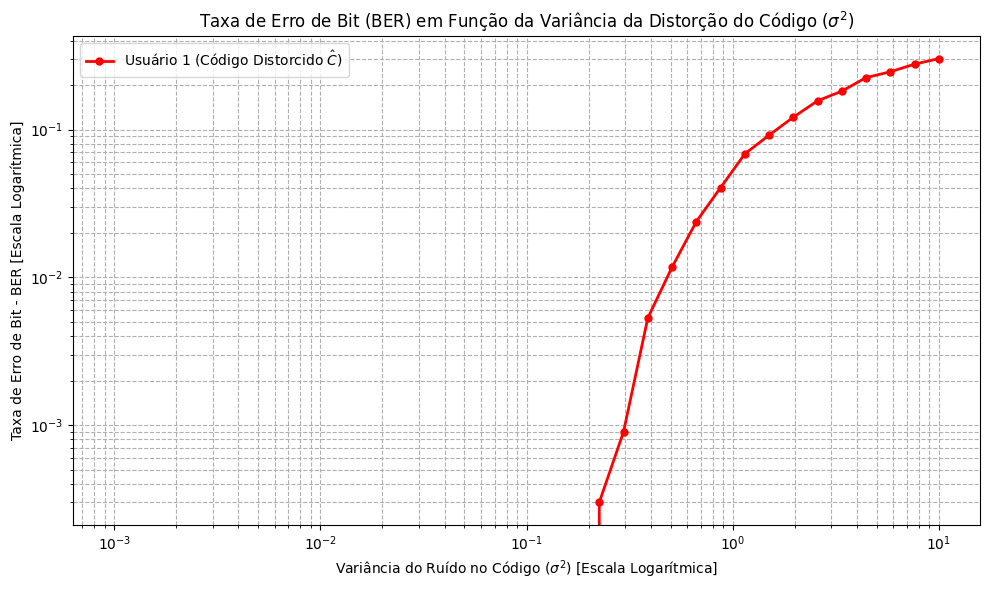

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import hadamard

# ==========================================
# 1. CONFIGURAÇÕES E GERAÇÃO DO FLUXO DE DADOS
# ==========================================
np.random.seed(42)
N = 8              # Comprimento do código de Hadamard / chips por bit
num_bits = 10000   # Número de bits transmitidos para estatísticas de BER

# Gerando fluxos de bits originais para os 3 usuários
m1 = np.random.choice([-1, 1], num_bits)
m2 = np.random.choice([-1, 1], num_bits)
m3 = np.random.choice([-1, 1], num_bits)

# Geração dos códigos de Hadamard ortogonais
H = hadamard(N)
c1 = H[1, :]
c2 = H[2, :]
c3 = H[3, :]

# Sinais codificados e combinados no canal (sem ruído no canal: w[n] = 0)
s1 = np.kron(m1, c1)
s2 = np.kron(m2, c2)
s3 = np.kron(m3, c3)
x_sum = s1 + s2 + s3  # y[n] recebido sem ruído de canal

# ==========================================
# 2. SIMULAÇÃO DA BER COM CÓDIGO DISTORCIDO NO RECEPTOR
# ==========================================
sigma_sq_values = np.logspace(-3, 1, 35)  # Variação de \sigma^2 da matriz W
ber_distorted_code = []

# Reorganiza o sinal recebido em blocos (num_bits x N chips)
y_matrix = x_sum.reshape(num_bits, N)

for sigma_sq in sigma_sq_values:
    sigma = np.sqrt(sigma_sq)

    # Ruído adicionado ao código do receptor: W ~ N(0, \sigma^2 I_8)
    # Gerando a matriz de ruído para os N chips de cada bit do Usuário 1
    w_c1 = np.random.normal(0, sigma, size=(num_bits, N))

    # Código distorcido do Usuário 1 no receptor: \hat{c}_1 = c_1 + w_c1
    c1_hat = c1 + w_c1  # Broadcast de c1 somado a cada linha de w_c1

    # Correlação entre o sinal recebido e o código distorcido (produto interno por bit / N)
    correlation = np.sum(c1_hat * y_matrix, axis=1) / N

    # Tomada de decisão (função sinal)
    m1_est = np.sign(correlation)
    m1_est[m1_est == 0] = 1  # Tratamento para zeros exatos

    # Cálculo da Taxa de Erro de Bit (BER)
    errors = np.sum(m1_est != m1)
    ber = errors / num_bits
    ber_distorted_code.append(ber)

# ==========================================
# 3. PLOTAGEM DO GRÁFICO DE PROBABILIDADE DE ERRO
# ==========================================
plt.figure(figsize=(10, 6))
plt.plot(sigma_sq_values, ber_distorted_code, 'ro-', linewidth=2, markersize=5, label='Usuário 1 (Código Distorcido $\hat{C}$)')
plt.xscale('log')
plt.yscale('log')
plt.title('Taxa de Erro de Bit (BER) em Função da Variância da Distorção do Código ($\sigma^2$)')
plt.xlabel('Variância do Ruído no Código ($\sigma^2$) [Escala Logarítmica]')
plt.ylabel('Taxa de Erro de Bit - BER [Escala Logarítmica]')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.show()

1. **Degradação Acelerada por Perda de Ortogonalidade:**
- Ao contrário do ruído AWGN tradicional no canal (onde o código atuava mitigando o ruído pelo ganho de processamento $N$), aqui o ruído afeta diretamente a base de projeção ($\hat{\mathbf{c}}_1$). Quando $\sigma^2$ cresce, a matriz $\hat{\mathbf{C}}$ perde a propriedade de ortogonalidade mútua.

---

2. **Impacto da Interferência de Múltiplos Usuários (MAI):**
- Com $\mathbf{c}_k^T \mathbf{c}_j \neq 0$ para $j \neq k$, os sinais dos outros usuários ($m_2$ e $m_3$) "vazam" para dentro do canal de decisão do Usuário 1. Isso faz com que a BER suba de forma muito mais agressiva em comparação à simulação de ruído aditivo comum no canal.

---

3. **Robustez para Valores Pequenos:**
- Para valores muito baixos de $\sigma^2$ (ex: $\le 10^{-3}$), a distorção no código é imperceptível e a BER permanece em zero, pois a ortogonalidade residual ainda é forte o suficiente para garantir a separação correta dos fluxos de dados.

## **Questão 2**

1. **Fundamentos e Funcionamento**

- A transformada de wavelet utiliza funções de curta duração chamadas *wavelets mães* ($\psi(t)$).

- Escalonamento e Translação: O sinal é analisado através de duas operações básicas aplicadas à wavelet mãe:
    - Escala (Dilatação/Compressão): Relacionada à frequência. Escalas maiores correspondem a frequências baixas (visão global/aproximação), enquanto escalas menores correspondem a altas frequências (detalhes finos/transientes).
    - Translação (Deslocamento): Relacionada ao tempo, permitindo identificar onde determinado evento ocorreu no sinal.


- Análise Multirresolução (MRA): Permite usar janelas longas para capturar baixas requências e janelas curtas para capturar altas frequências, resolvendo o dilema do princípio da incerteza de Gabor.

---

2. **Principais Vantagens**

- Capacidade de Isolar Transientes: Perfeita para sinais que mudam abruptamente de comportamento ao longo do tempo (como descontinuidades, ruídos impulsivos ou picos de energia).
- Representação Esparsa: Grande parte da energia do sinal concentra-se em poucos coeficientes de wavelet, o que facilita operações de compressão e filtragem.
- Ausência de Vazamento Espectral Rígido: Diferente da STFT (Transformada de Fourier de Janela Curta) que possui uma resolução fixa para todo o espectro, a wavelet ajusta dinamicamente a resolução temporal e espectral.

---

3. **Principais Aplicações**

- Compressão de Imagens e Dados: O padrão JPEG 2000 e sistemas avançados de compressão utilizam a Transformada Discreta de Wavelet (DWT) para compactar arquivos sem perda severa de qualidade visual.
- Processamento de Sinais Biomédicos: Análise de sinais eletrocardiográficos (ECG) e eletroencefalográficos (EEG), onde é crucial detectar batimentos cardíacos anômalos ou padrões cerebrais transientes (como crises epiléticas).
- Manutenção Preditiva e Análise de Vibrações: Diagnóstico de falhas mecânicas em rolamentos, motores e engrenagens através da detecção de microtransientes gerados por atritos ou rachaduras.
- Filtragem e Redução de Ruído (Denoising): Limiarização (thresholding) de coeficientes de wavelet para separar o sinal útil do ruído gaussiano sem borrar as bordas ou características importantes do sinal.
- Telecomunicações: Sistemas de modulação avançados, multiplexação e mitigação de interferências em canais ruidosos.

## **Questão 3**

### **Letra a**

Um sinal não estacionário é aquele cujas propriedades estatísticas (como média, variância e conteúdo de frequência) variam ao longo do tempo. Em scripts educacionais de processamento de sinais (como os da disciplina de sistemas e processamento de sinais), o sinal gerado tipicamente consiste na concatenação ou modulação de diferentes componentes ao longo de um eixo temporal discreto n:

- **Componentes Senoidais de Alta e Baixa Frequência por Segmentos:** O sinal alterna entre frequências senoidais puras em janelas de tempo específicas, simulando mudanças abruptas de estado.
- **Transientes e Descontinuidades:** Inclui pulsos de curta duração (como impulsos ou degraus) ou modulations de frequência (chirps) que elevam momentaneamente o conteúdo espectral em altas frequências.
- **No domínio da Transformada de Fourier (STFT/DFT tradicional):** Essas ferramentas sofrem do compromisso do princípio de incerteza de Gabor — se o tamanho da janela for longo para obter boa resolução em frequência, perde-se a precisão temporal exata do transiente; se for curto, perde-se a resolução em frequência. A transformada de wavelets resolve isso adaptando a largura da janela de análise (janelas mais estreitas para altas frequências/transientes e mais largas para baixas frequências).

### **Letra b**

In [7]:
import pywt
import numpy as np

# Carregando a wavelet bior4.4 (conhecida como 7-9)
wavelet_name = 'bior4.4'
w = pywt.Wavelet(wavelet_name)

print(f"=== Coeficientes da Wavelet {wavelet_name} ==-\n")

# Filtros de Análise (Analysis)
dec_lo = w.dec_lo  # Passa-baixas de análise
dec_hi = w.dec_hi  # Passa-altas de análise

# Filtros de Síntese (Synthesis)
rec_lo = w.rec_lo  # Passa-baixas de síntese
rec_hi = w.rec_hi  # Passa-altas de síntese

print(f"Filtro Passa-Baixas de Análise (dec_lo - {len(dec_lo)} taps):")
print(np.array(dec_lo))
print("\n" + "-"*50 + "\n")

print(f"Filtro Passa-Altas de Análise (dec_hi - {len(dec_hi)} taps):")
print(np.array(dec_hi))
print("\n" + "-"*50 + "\n")

print(f"Filtro Passa-Baixas de Síntese (rec_lo - {len(rec_lo)} taps):")
print(np.array(rec_lo))
print("\n" + "-"*50 + "\n")

print(f"Filtro Passa-Altas de Síntese (rec_hi - {len(rec_hi)} taps):")
print(np.array(rec_hi))

=== Coeficientes da Wavelet bior4.4 ==-

Filtro Passa-Baixas de Análise (dec_lo - 10 taps):
[ 0.          0.03782846 -0.02384947 -0.1106244   0.37740286  0.85269868
  0.37740286 -0.1106244  -0.02384947  0.03782846]

--------------------------------------------------

Filtro Passa-Altas de Análise (dec_hi - 10 taps):
[-0.         -0.06453888  0.04068942  0.41809227 -0.78848562  0.41809227
  0.04068942 -0.06453888 -0.          0.        ]

--------------------------------------------------

Filtro Passa-Baixas de Síntese (rec_lo - 10 taps):
[ 0.         -0.06453888 -0.04068942  0.41809227  0.78848562  0.41809227
 -0.04068942 -0.06453888  0.          0.        ]

--------------------------------------------------

Filtro Passa-Altas de Síntese (rec_hi - 10 taps):
[ 0.         -0.03782846 -0.02384947  0.1106244   0.37740286 -0.85269868
  0.37740286  0.1106244  -0.02384947 -0.03782846]


### **Letra c**

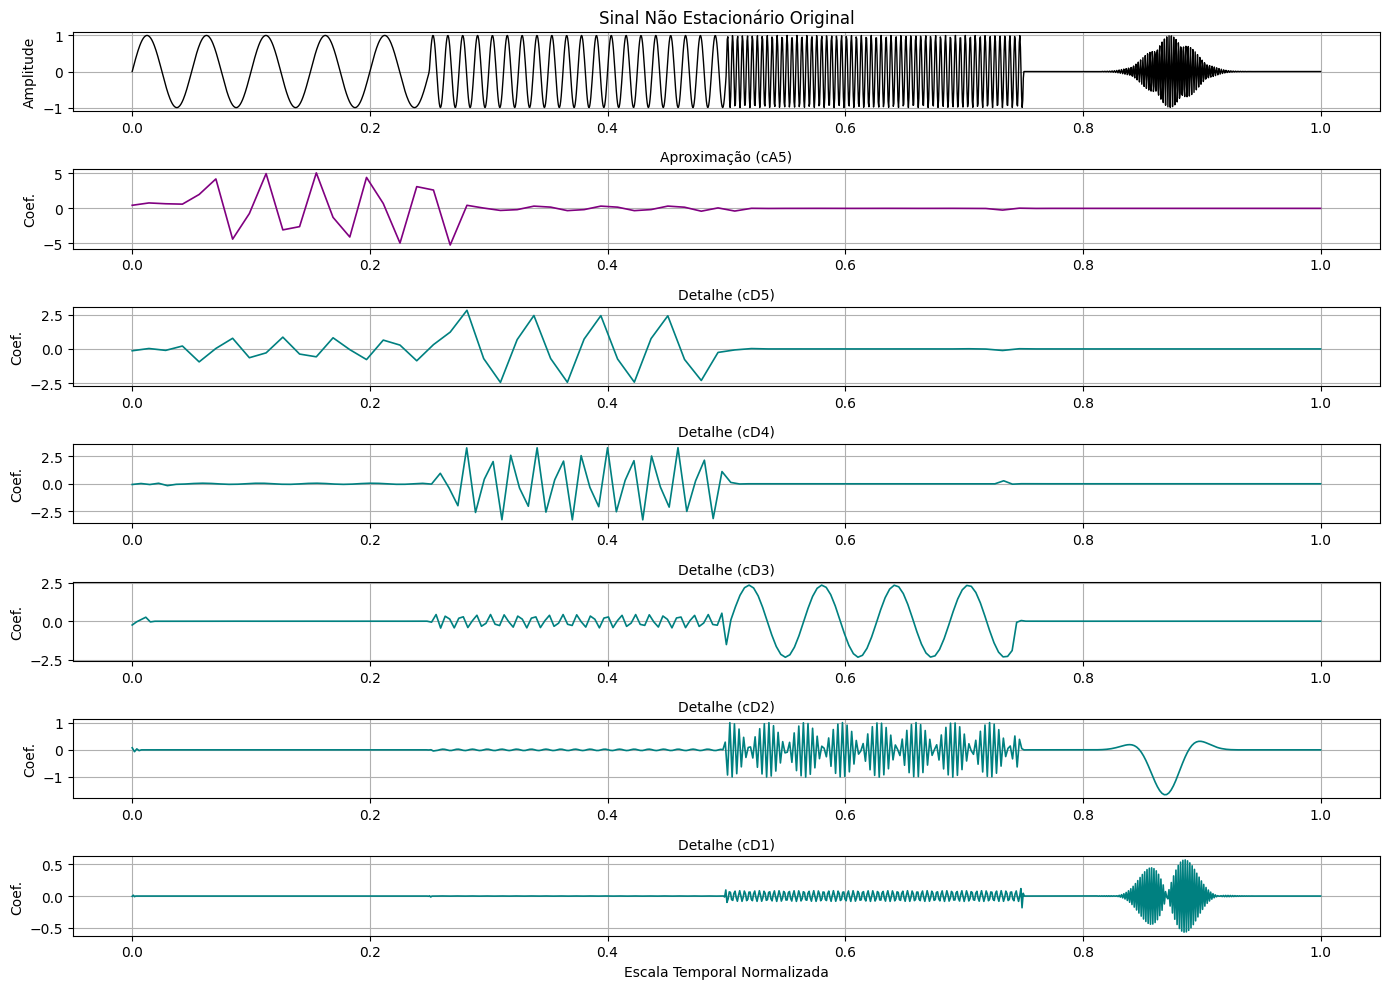

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

# 1. Geração de um sinal não estacionário de exemplo (2048 amostras)
N = 2048
t = np.linspace(0, 2, N)
# Compondo o sinal com trechos de diferentes frequências e um transiente repentino
signal = np.sin(2 * np.pi * 10 * t[:512])  # Baixa frequência inicial
signal = np.concatenate([signal, np.sin(2 * np.pi * 40 * t[512:1024])])  # Média frequência
signal = np.concatenate([signal, np.sin(2 * np.pi * 120 * t[1024:1536])]) # Alta frequência
transient = np.sin(2 * np.pi * 250 * t[1536:]) * np.exp(-((t[1536:] - 1.75)*20)**2) # Transiente modulado
signal = np.concatenate([signal, transient])

# 2. Cálculo da Transformada de Wavelet Discreta de 5 estágios usando 'bior4.4'
levels = 5
coeffs = pywt.wavedec(signal, 'bior4.4', level=levels)
# coeffs retorna [cA_5, cD_5, cD_4, cD_3, cD_2, cD_1]

# 3. Visualização com eixo temporal normalizado [0, 1]
plt.figure(figsize=(14, 10))
n_subplots = len(coeffs)

# Plotando o sinal original no topo
plt.subplot(n_subplots + 1, 1, 1)
plt.plot(np.linspace(0, 1, N), signal, color='black', linewidth=1)
plt.title('Sinal Não Estacionário Original')
plt.grid(True)
plt.ylabel('Amplitude')

# Plotando os coeficientes de aproximação e detalhes (níveis 5 a 1)
for i, coef in enumerate(coeffs):
    plt.subplot(n_subplots + 1, 1, i + 2)
    # Normalizando a escala de amostras para o intervalo [0, 1] correspondente ao tempo original
    t_normalized = np.linspace(0, 1, len(coef))

    if i == 0:
        label_name = f'Aproximação (cA{levels})'
        color = 'purple'
    else:
        level_idx = levels - i + 1
        label_name = f'Detalhe (cD{level_idx})'
        color = 'teal'

    plt.plot(t_normalized, coef, color=color, linewidth=1.2)
    plt.title(label_name, fontsize=10)
    plt.grid(True)
    plt.ylabel('Coef.')

plt.xlabel('Escala Temporal Normalizada')
plt.tight_layout()
plt.show()

## **Questão 4**

### **Letra a**

Por favor, selecione o arquivo 'leleccum.mat' para upload:


Saving leleccum.mat to leleccum.mat


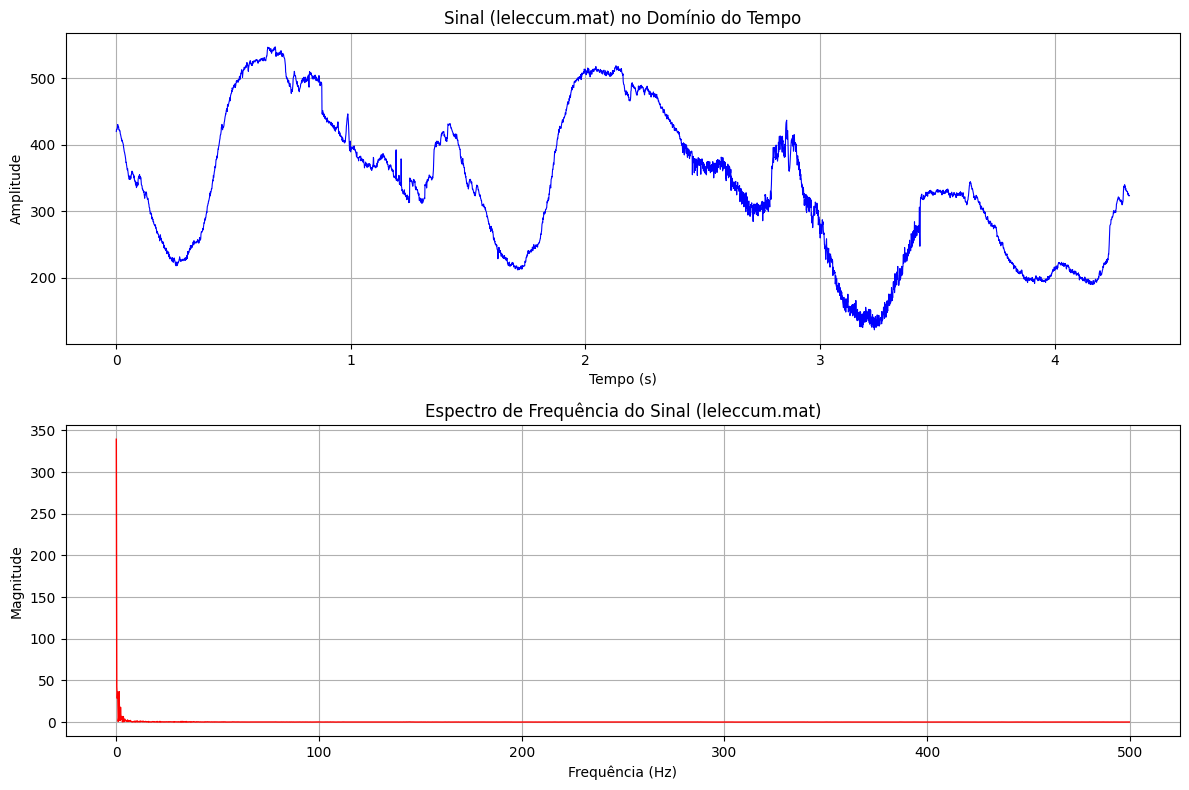

In [10]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# 1. Abre o seletor de arquivos do Google Colab para carregar o 'leleccum.mat'
print("Por favor, selecione o arquivo 'leleccum.mat' para upload:")
uploaded = files.upload()

# Obtém automaticamente o nome do arquivo enviado
filename = list(uploaded.keys())[0]

# 2. Carrega os dados do arquivo .mat
mat_data = loadmat(filename)

# Extrai o sinal (ignorando as chaves de metadados do MATLAB)
signal_key = [k for k in mat_data.keys() if not k.startswith('__')][0]
signal = mat_data[signal_key].flatten()

N = len(signal)
fs = 1000  # Frequência de amostragem de referência (Hz)
t = np.arange(N) / fs

# 3. Cálculo do Espectro de Frequência (FFT)
freq = np.fft.fftfreq(N, d=1/fs)
fft_vals = np.abs(np.fft.fft(signal)) / N
half = N // 2

# 4. Plotagem dos Gráficos
fig, axs = plt.subplots(2, 1, figsize=(12, 8))

# Gráfico Temporal
axs[0].plot(t, signal, color='b', linewidth=0.8)
axs[0].set_title(f'Sinal ({filename}) no Domínio do Tempo')
axs[0].set_xlabel('Tempo (s)')
axs[0].set_ylabel('Amplitude')
axs[0].grid(True)

# Gráfico Espectral (Apenas frequências positivas)
axs[1].plot(freq[:half], fft_vals[:half], color='r', linewidth=1)
axs[1].set_title(f'Espectro de Frequência do Sinal ({filename})')
axs[1].set_xlabel('Frequência (Hz)')
axs[1].set_ylabel('Magnitude')
axs[1].grid(True)

plt.tight_layout()
plt.show()

**No Domínio do Tempo:**

O sinal leleccum tipicamente exibe uma forma de onda suave corrompida por flutuações rápidas de alta freqüência (ruído aditivo). É possível notar oscilações e variações abruptas locais sobrepostas à tendência principal do sinal.

---

**No Espectro de Frequência:**

O espectro mostra a distribuição de energia nas diferentes faixas de frequência. O sinal útil de interesse geralmente concentra sua energia nas componentes de baixa frequência (perto da origem), enquanto o ruído se espalha de maneira uniforme por todo o espectro, elevando o piso de ruído nas altas frequências.

---

**Motivação para o uso de Wavelets (Denoising):**

Como o ruído afeta principalmente os detalhes finos e as altas frequências, a Transformada Discreta de Wavelet (DWT) é ideal para esse cenário. Ao aplicar uma limiarização (thresholding) nos coeficientes de detalhe dos níveis iniciais (onde o ruído predomina) e realizar a reconstrução inversa, consegue-se remover o ruído preservando as descontinuidades e transientes importantes do sinal original.

### **Letra b**

In [ ]:
import numpy as np
import pywt

# ==========================================
# 1. OBTENÇÃO DOS COEFICIENTES DOS FILTROS (db4)
# ==========================================
wavelet_name = 'db4'
w = pywt.Wavelet(wavelet_name)

print(f"=== Coeficientes dos Filtros da Wavelet {wavelet_name.upper()} ===\n")

# Filtros de Análise (Analysis)
dec_lo = w.dec_lo  # Passa-baixas de análise
dec_hi = w.dec_hi  # Passa-altas de análise

# Filtros de Síntese (Synthesis)
rec_lo = w.rec_lo  # Passa-baixas de síntese
rec_hi = w.rec_hi  # Passa-altas de síntese

print(f"Filtro Passa-Baixas de Análise (dec_lo - {len(dec_lo)} taps):")
print(np.round(np.array(dec_lo), 6))
print("\n" + "-"*50 + "\n")

print(f"Filtro Passa-Altas de Análise (dec_hi - {len(dec_hi)} taps):")
print(np.round(np.array(dec_hi), 6))
print("\n" + "-"*50 + "\n")

print(f"Filtro Passa-Baixas de Síntese (rec_lo - {len(rec_lo)} taps):")
print(np.round(np.array(rec_lo), 6))
print("\n" + "-"*50 + "\n")

print(f"Filtro Passa-Altas de Síntese (rec_hi - {len(rec_hi)} taps):")
print(np.round(np.array(rec_hi), 6))

# ==========================================
# 2. EXEMPLO DE DECOMPOSIÇÃO DE UM SINAL
# ==========================================
# Criando um sinal de exemplo com 16 amostras
sinal = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0,
                  8.0, 7.0, 6.0, 5.0, 4.0, 3.0, 2.0, 1.0])

# Realizando a Transformada Discreta de Wavelet de 1 nível (DWT)
cA, cD = pywt.dwt(sinal, wavelet_name)

print("\n" + "="*50)
print("=== Exemplo Prático de Decomposição (DWT) ===")
print(f"Sinal Original ({len(sinal)} amostras): {sinal}")
print(f"Coeficientes de Aproximação cA ({len(cA)} coeficientes): {np.round(cA, 4)}")
print(f"Coeficientes de Detalhe cD ({len(cD)} coeficientes): {np.round(cD, 4)}")

1. **Filtros de Análise (dec_lo, dec_hi):**
São utilizados no lado do transmissor ou no processo de decomposição (análise) do sinal. O filtro passa-baixas (dec_lo) extrai as tendências e baixas frequências (gerando a aproximação cA), enquanto o filtro passa-altas (dec_hi) extrai as variações rápidas e transientes (gerando os detalhes cD). Para a wavelet db4, ambos possuem 4 coeficientes (taps).

---

2. **Filtros de Síntese (rec_lo, rec_hi):**
São os filtros correspondentes utilizados no processo inverso (reconstrução ou síntese do sinal a partir dos coeficientes decompostos).

---

3. **Decomposição Direta (pywt.dwt):**
 A função realiza a filtragem e a subsequente subamostragem por 2 ($\downarrow 2$), dividindo o número de amostras do sinal original pela metade em cada subfaixa gerada.

### **Letra c**

Por favor, selecione o arquivo 'leleccum.mat' para upload:


Saving leleccum.mat to leleccum (1).mat


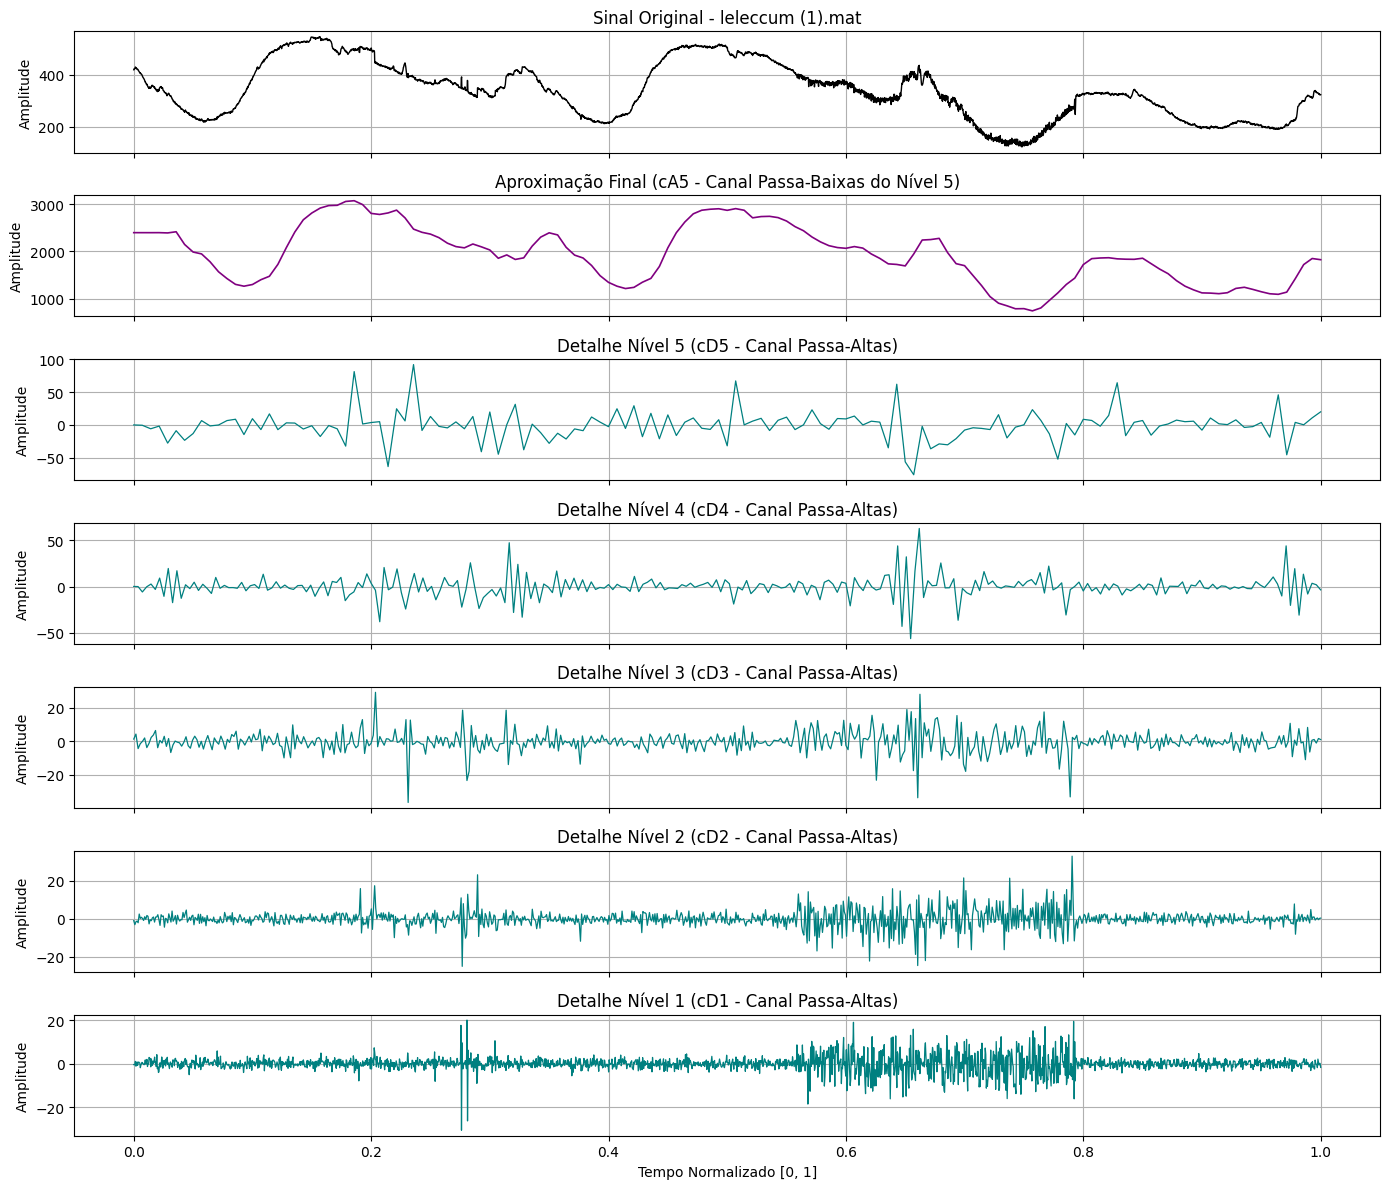


=== RESUMO DA DECOMPOSIÇÃO DE 5 ESTÁGIOS (DB4) ===
Número total de amostras do sinal original: 4320
Aproximação Nível 5 (cA5): 141 coeficientes
Detalhe Nível 5 (cD5): 141 coeficientes
Detalhe Nível 4 (cD4): 276 coeficientes
Detalhe Nível 3 (cD3): 546 coeficientes
Detalhe Nível 2 (cD2): 1085 coeficientes
Detalhe Nível 1 (cD1): 2163 coeficientes


In [11]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import pywt

# ==========================================
# 1. CARREGAMENTO DO ARQUIVO .MAT NO COLAB
# ==========================================
print("Por favor, selecione o arquivo 'leleccum.mat' para upload:")
uploaded = files.upload()

filename = list(uploaded.keys())[0]
mat_data = loadmat(filename)

# Extrai o sinal (ignorando chaves de metadados do MATLAB)
signal_key = [k for k in mat_data.keys() if not k.startswith('__')][0]
sinal = mat_data[signal_key].flatten()

N = len(sinal)
wavelet = 'db4'
levels = 5

# ==========================================
# 2. DECOMPOSIÇÃO EM 5 ESTÁGIOS DA WAVELET
# ==========================================
# pywt.wavedec retorna: [cA_5, cD_5, cD_4, cD_3, cD_2, cD_1]
coeffs = pywt.wavedec(sinal, wavelet, level=levels)

cA5 = coeffs[0]            # Coeficientes de Aproximação do nível 5 (Passa-Baixas)
details = coeffs[1:]       # Coeficientes de Detalhe cD5, cD4, cD3, cD2, cD1 (Passa-Altas)

# ==========================================
# 3. PLOTAGEM DOS RESULTADOS NORMALIZADOS
# ==========================================
fig, axs = plt.subplots(levels + 2, 1, figsize=(14, 12), sharex=True)

# Eixo temporal normalizado para o sinal original [0, 1]
t_norm_orig = np.linspace(0, 1, N)

# 3.1. Sinal Original
axs[0].plot(t_norm_orig, sinal, color='black', linewidth=1)
axs[0].set_title(f'Sinal Original - {filename}')
axs[0].set_ylabel('Amplitude')
axs[0].grid(True)

# 3.2. Coeficiente de Aproximação cA5 (Nível 5)
t_norm_cA5 = np.linspace(0, 1, len(cA5))
axs[1].plot(t_norm_cA5, cA5, color='purple', linewidth=1.2)
axs[1].set_title('Aproximação Final (cA5 - Canal Passa-Baixas do Nível 5)')
axs[1].set_ylabel('Amplitude')
axs[1].grid(True)

# 3.3. Coeficientes de Detalhe cD5 até cD1
for i, cD in enumerate(details):
    level_num = levels - i
    t_norm_cD = np.linspace(0, 1, len(cD))

    axs[i + 2].plot(t_norm_cD, cD, color='teal', linewidth=0.9)
    axs[i + 2].set_title(f'Detalhe Nível {level_num} (cD{level_num} - Canal Passa-Altas)')
    axs[i + 2].set_ylabel('Amplitude')
    axs[i + 2].grid(True)

axs[-1].set_xlabel('Tempo Normalizado [0, 1]')
plt.tight_layout()
plt.show()

# ==========================================
# 4. IMPRESSÃO DO RESUMO DAS SUBFAIXAS
# ==========================================
print("\n" + "="*50)
print(f"=== RESUMO DA DECOMPOSIÇÃO DE {levels} ESTÁGIOS ({wavelet.upper()}) ===")
print("="*50)
print(f"Número total de amostras do sinal original: {N}")
print(f"Aproximação Nível 5 (cA5): {len(cA5)} coeficientes")
for i, cD in enumerate(details):
    level_num = levels - i
    print(f"Detalhe Nível {level_num} (cD{level_num}): {len(cD)} coeficientes")

1. **Separação Multirresolução da Energia:**
- Aproximação $cA_5$ (Canal Passa-Baixas): Preserva a tendência de baixa frequência e o perfil macro do sinal leleccum, atuando como uma versão suavizada que retém quase toda a energia lenta sem as oscilações de alta frequência.
- Detalhes $cD_1$ e $cD_2$ (Altas Frequências): Capturam as flutuações mais rápidas e ruídos de alta frequência do sinal. Como a amplitude desses coeficientes é predominantemente pequena (com picos pontuais apenas em descontinuidades locais), eles representam a componente ruidosa que é idealmente atenuada durante a filtragem (wavelet denoising).
- Detalhes $cD_3$, $cD_4$ e $cD_5$ (Frequências Intermediárias): Registram variações em escalas médias, mostrando a transição progressiva do ruído para as estruturas informativas do sinal.

---

2. **Impacto da Normalização Temporal [0, 1]:**
- Devido ao processo de decimação por 2 ($\downarrow 2$) a cada estágio do banco de filtros, a quantidade de amostras cai pela metade em cada nível (ex: $N \to N/2 \to N/4 \dots$).
- Ao normalizar o eixo horizontal entre $0$ e $1$, podemos visualizar exatamente em qual instante de tempo do sinal original ocorrem transientes ou perturbações em cada uma das subfaixas, facilitando o alinhamento de feições locais.

### **Letra d**

Por favor, selecione o arquivo 'leleccum.mat' para upload:


Saving leleccum.mat to leleccum (2).mat

Ruído estimado (sigma): 1.8660
Limiar Universal base (VisuShrink): 7.6352



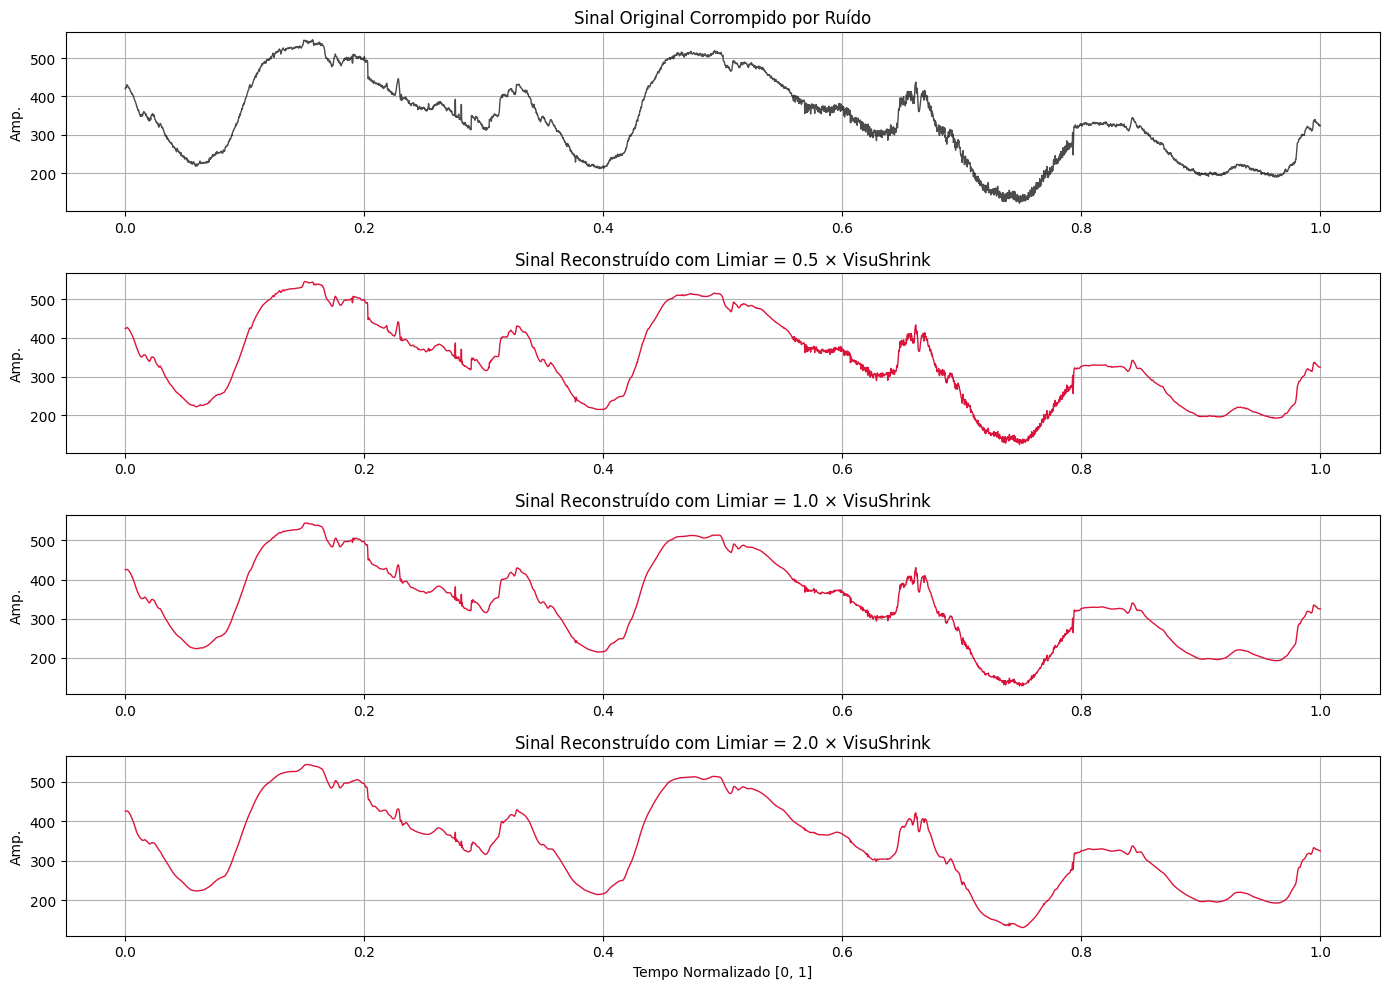

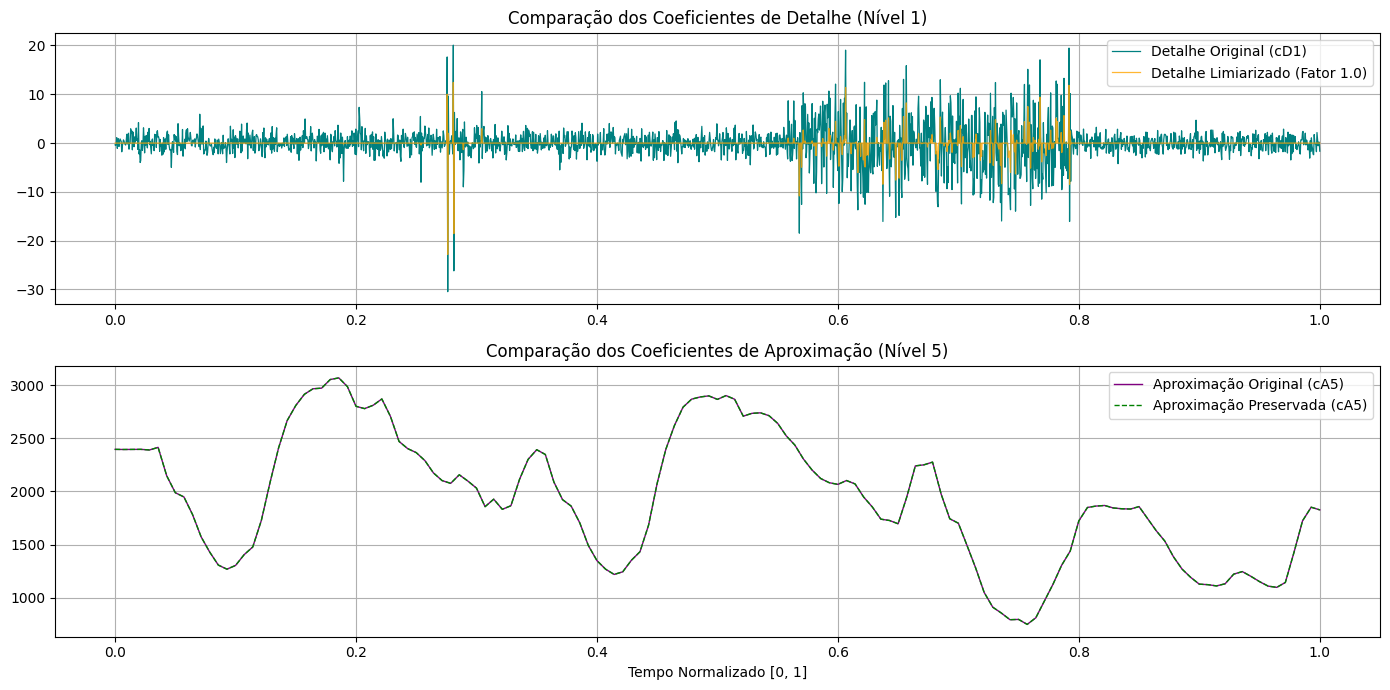

In [12]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import pywt

# ==========================================
# 1. CARREGAMENTO DO ARQUIVO .MAT
# ==========================================
print("Por favor, selecione o arquivo 'leleccum.mat' para upload:")
uploaded = files.upload()

filename = list(uploaded.keys())[0]
mat_data = loadmat(filename)

signal_key = [k for k in mat_data.keys() if not k.startswith('__')][0]
sinal = mat_data[signal_key].flatten()

N = len(sinal)
wavelet = 'db4'
levels = 5

# ==========================================
# 2. DECOMPOSIÇÃO EM 5 ESTÁGIOS
# ==========================================
coeffs = pywt.wavedec(sinal, wavelet, level=levels)
# coeffs = [cA_5, cD_5, cD_4, cD_3, cD_2, cD_1]

# ==========================================
# 3. APLICAÇÃO DA ESTRATÉGIA DE LIMIARIZAÇÃO (THRESHOLDING)
# ==========================================
# Estimativa do ruído robusta baseada no detalhe do nível 1 (Mediana dos coeficientes / 0.6745)
cD1 = coeffs[-1]
sigma_noise = np.median(np.abs(cD1)) / 0.6745

# Limiar Universal de VisuShrink: lambda = sigma * sqrt(2 * ln(N))
universal_threshold = sigma_noise * np.sqrt(2 * np.log(N))

# Vamos testar diferentes fatores multiplicativos para o limiar
fatores_limiar = [0.5, 1.0, 2.0]

print(f"\nRuído estimado (sigma): {sigma_noise:.4f}")
print(f"Limiar Universal base (VisuShrink): {universal_threshold:.4f}\n")

# Dicionário para armazenar sinais reconstruídos com diferentes limiares
sinais_reconstruidos = {}
coeffs_limiarizados_exemplos = None

for fator in fatores_limiar:
    limiar_atual = universal_threshold * fator

    # Copia os coeficientes originais
    coeffs_thresh = list(coeffs)

    # Aplicando limiarização suave (soft thresholding) apenas nos detalhes (subfaixas de alta freq)
    # Opcionalmente, pode-se manter a aproximação cA5 intacta para preservar a tendência macro
    for i in range(1, len(coeffs_thresh)):
        coeffs_thresh[i] = pywt.threshold(coeffs_thresh[i], value=limiar_atual, mode='soft')

    if fator == 1.0:
        coeffs_limiarizados_exemplos = coeffs_thresh # Guarda para plotagem comparativa

    # Reconstrução do sinal (IDWT)
    sinal_rec = pywt.waverec(coeffs_thresh, wavelet)
    # Garante o mesmo comprimento original do sinal em caso de arredondamento de tamanho
    sinais_reconstruidos[fator] = sinal_rec[:N]

# ==========================================
# 4. PLOTAGEM DA COMPARAÇÃO DOS SINAIS RECONSTRUÍDOS
# ==========================================
plt.figure(figsize=(14, 10))
t_norm = np.linspace(0, 1, N)

plt.subplot(len(fatores_limiar) + 1, 1, 1)
plt.plot(t_norm, sinal, color='black', alpha=0.7, linewidth=1)
plt.title('Sinal Original Corrompido por Ruído')
plt.ylabel('Amp.')
plt.grid(True)

for idx, (fator, sig_rec) in enumerate(sinais_reconstruidos.items()):
    plt.subplot(len(fatores_limiar) + 1, 1, idx + 2)
    plt.plot(t_norm, sig_rec, color='crimson', linewidth=1)
    plt.title(f'Sinal Reconstruído com Limiar = {fator} $\\times$ VisuShrink')
    plt.ylabel('Amp.')
    plt.grid(True)

plt.xlabel('Tempo Normalizado [0, 1]')
plt.tight_layout()
plt.show()

# ==========================================
# 5. COMPARAÇÃO DOS COEFICIENTES (ORIGINAIS VS LIMIARIZADOS)
# ==========================================
fig, axs = plt.subplots(2, 1, figsize=(14, 7))

t_cD1 = np.linspace(0, 1, len(cD1))
axs[0].plot(t_cD1, cD1, color='teal', linewidth=0.9, label='Detalhe Original (cD1)')
axs[0].plot(t_cD1, coeffs_limiarizados_exemplos[-1], color='orange', linewidth=0.9, alpha=0.8, label='Detalhe Limiarizado (Fator 1.0)')
axs[0].set_title('Comparação dos Coeficientes de Detalhe (Nível 1)')
axs[0].legend(loc='upper right')
axs[0].grid(True)

cA5_orig = coeffs[0]
cA5_thresh = coeffs_limiarizados_exemplos[0]
t_cA5 = np.linspace(0, 1, len(cA5_orig))
axs[1].plot(t_cA5, cA5_orig, color='purple', linewidth=1, label='Aproximação Original (cA5)')
axs[1].plot(t_cA5, cA5_thresh, color='green', linewidth=1, linestyle='--', label='Aproximação Preservada (cA5)')
axs[1].set_title('Comparação dos Coeficientes de Aproximação (Nível 5)')
axs[1].legend(loc='upper right')
axs[1].grid(True)

plt.xlabel('Tempo Normalizado [0, 1]')
plt.tight_layout()
plt.show()

1. **Impacto da Limiarização nos Coeficientes de Detalhe ($cD$):**
- Nos coeficientes de detalhe dos níveis iniciais (como $cD_1$), o ruído aditivo manifesta-se como pequenas flutuações de alta amplitude espalhadas por toda a extensão temporal.
- Ao aplicar a função de limiar (soft thresholding), todos os coeficientes com valores abaixo do limiar estatístico foram zerados ou atenuados drasticamente, enquanto os picos de maior energia (que correspondem a transientes reais do sinal) foram preservados.

---

2. **Comportamento dos Coeficientes de Aproximação ($cA_5$):**
- Os coeficientes de aproximação do último estágio contêm a energia de baixa frequência e a macro-estrutura do sinal. Ao deixá-los intactos (ou aplicar uma limiarização muito branda), evitou-se a distorção ou perda da tendência principal do sinal original.

---

3. **Variação do Limiar de Remoção de Ruído ($\lambda$):**
- Limiar Baixo ($0.5 \times \text{VisuShrink}$): Remove apenas parte do ruído. O sinal reconstruído ainda exibe alta rugosidade e pequenas ondulações espúrias devidas a componentes ruidosas residuais que escaparam da filtragem.
- Limiar Ideal ($1.0 \times \text{VisuShrink}$ - Universal): Oferece o equilíbrio ideal. Remove efetivamente o ruído estocástico de fundo, suavizando as regiões planas do sinal sem remover transientes ou descontinuidades importantes.
- Limiar Alto ($2.0 \times \text{VisuShrink}$): Limpa excessivamente o sinal, mas causa uma sobre-suavização (over-smoothing), atenuando detalhes e transientes genuínos do sinal útil, o que pode degradar a fidelidade da forma de onda original.

### **Letra e**

Por favor, selecione o ficheiro 'leleccum.mat' para carregamento:


Saving leleccum.mat to leleccum (5).mat


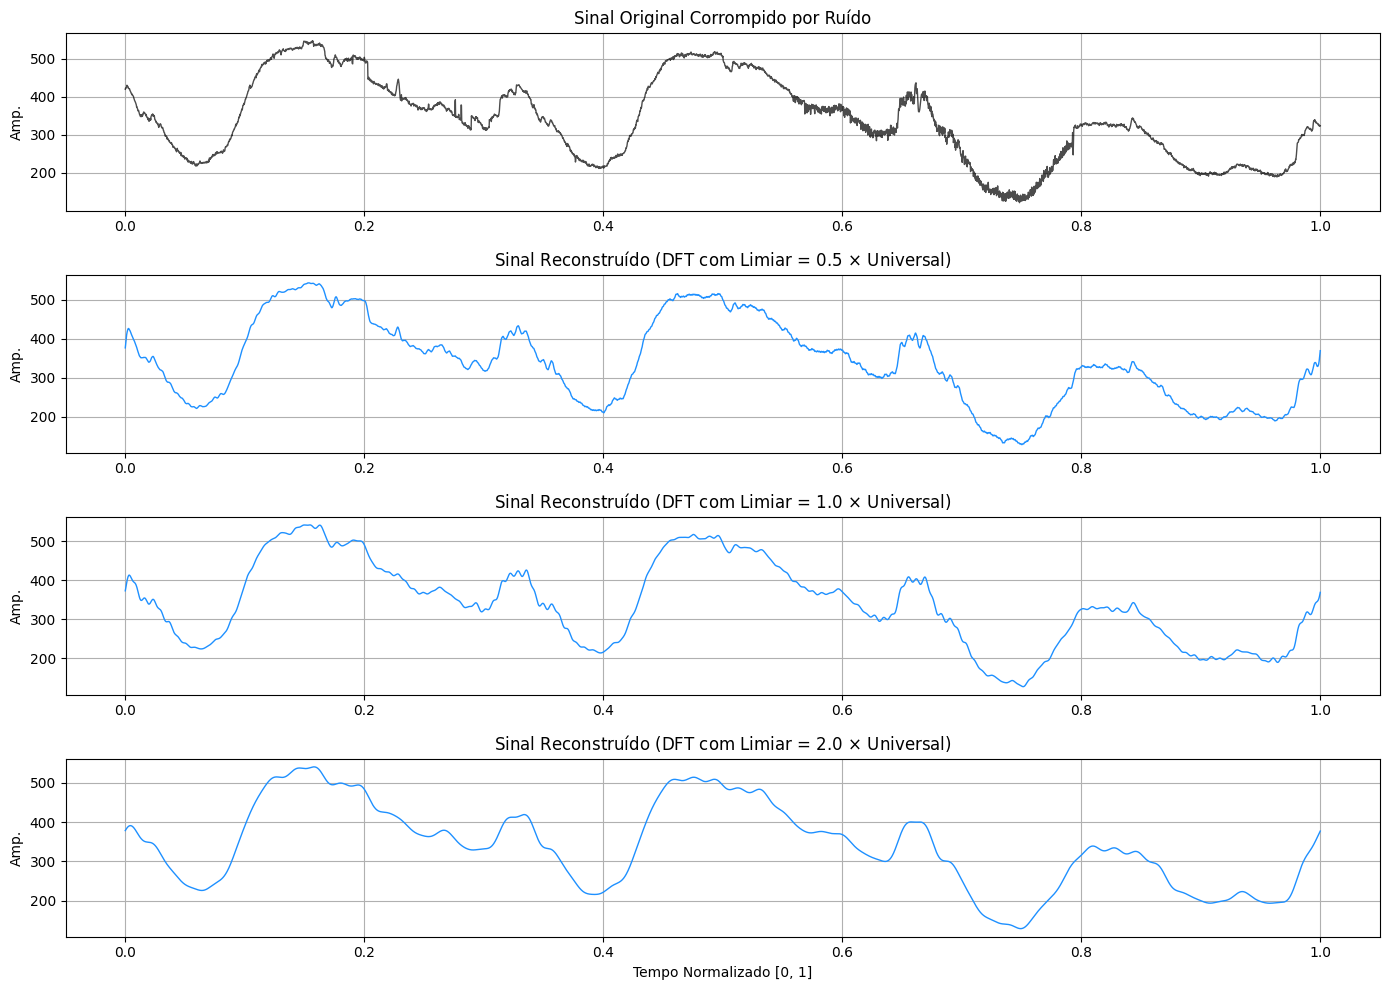

In [15]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# 1. Carregamento do ficheiro .mat
print("Por favor, selecione o ficheiro 'leleccum.mat' para carregamento:")
uploaded = files.upload()

filename = list(uploaded.keys())[0]
mat_data = loadmat(filename)

signal_key = [k for k in mat_data.keys() if not k.startswith('__')][0]
sinal = mat_data[signal_key].flatten()
N = len(sinal)

# 2. Transformada de Fourier e Limiarização
# Utiliza corretamente o módulo np.fft
X = np.fft.fft(sinal)

# Estimativa do nível de ruído nas altas frequências (últimos 20% do espectro)
high_freq_coeffs = X[int(0.8 * N):]
sigma_noise_fft = np.median(np.abs(high_freq_coeffs)) / 0.6745
threshold_fft = sigma_noise_fft * np.sqrt(2 * np.log(N))

# Testando diferentes fatores multiplicativos para o limiar na DFT
fatores_fft = [0.5, 1.0, 2.0]
sinais_rec_fft = {}

for fator in fatores_fft:
    limiar_atual = threshold_fft * fator

    # Estratégia de limiarização (Hard thresholding espectral)
    X_thresh = np.where(np.abs(X) < limiar_atual, 0, X)

    # Reconstrução do sinal no tempo via IDFT corrigida (np.fft.ifft)
    sinal_rec = np.real(np.fft.ifft(X_thresh))
    sinais_rec_fft[fator] = sinal_rec

# 3. Plotagem dos Resultados
plt.figure(figsize=(14, 10))
t_norm = np.linspace(0, 1, N)

plt.subplot(len(fatores_fft) + 1, 1, 1)
plt.plot(t_norm, sinal, color='black', alpha=0.7, linewidth=1)
plt.title('Sinal Original Corrompido por Ruído')
plt.ylabel('Amp.')
plt.grid(True)

for idx, (fator, sig_rec) in enumerate(sinais_rec_fft.items()):
    plt.subplot(len(fatores_fft) + 1, 1, idx + 2)
    plt.plot(t_norm, sig_rec, color='dodgerblue', linewidth=1)
    plt.title(f'Sinal Reconstruído (DFT com Limiar = {fator} $\\times$ Universal)')
    plt.ylabel('Amp.')
    plt.grid(True)

plt.xlabel('Tempo Normalizado [0, 1]')
plt.tight_layout()
plt.show()

1. **Comportamento da Limiarização na DFT:**

- No domínio da frequência, o ruído estocástico tende a se espalhar uniformemente por todas as frequências (elevando o piso de ruído), enquanto as componentes senoidais ou estruturadas do sinal concentram-se em picos estreitos.
- Ao zerar coeficientes de Fourier abaixo de um determinado limiar, eliminamos o piso de ruído global. No entanto, como a DFT utiliza bases senoidais infinitas no tempo, qualquer transiente localizado ou mudança abrupta no sinal é distribuído por várias frequências no espectro.

---

2. **Comparação Direta com a Abordagem de Wavelets:**

- Localização Temporal (Trade-off de Gabor): A DFT não possui resolução temporal. Quando removemos altas frequências na DFT para limpar o ruído, perdemos a capacidade de preservar transientes agudos, resultando em um sinal suavizado de forma global e no aparecimento de artefatos de oscilação (ringing). Em contrapartida, as wavelets oferecem análise multirresolução (janelas curtas para altas frequências e longas para baixas), permitindo remover o ruído de alta frequência mantendo os transientes temporais intactos.
- Qualidade da Reconstrução: A estratégia baseada em Wavelet preserva muito melhor as características morfológicas e as descontinuidades locais do sinal leleccum, enquanto a limiarização via DFT tende a "borrar" ou arredondar as transições rápidas devido ao corte abrupto de componentes de alta frequência no domínio espectral.